In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

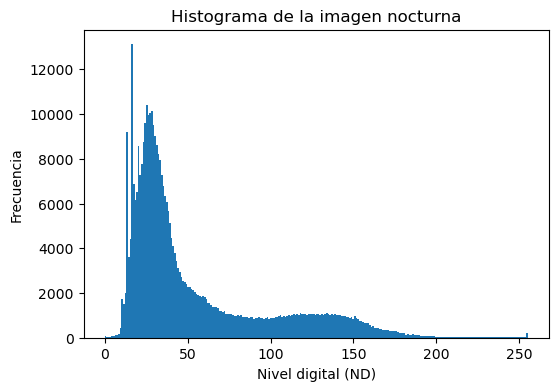

In [5]:
img = cv.imread('satelite_nocturno.jpg', cv.IMREAD_GRAYSCALE)

plt.figure(figsize=(6,4))
plt.hist(img.ravel(), bins=256, range=[0,255])
plt.title("Histograma de la imagen nocturna")
plt.xlabel("Nivel digital (ND)")
plt.ylabel("Frecuencia")
plt.show()

In [6]:
def mascara(img, t1, t2):
    filtro_bin = (img >= t1) & (img <= t2)
    return filtro_bin

In [7]:
def aplicamascara(img, t1, t2):
    filtro = mascara(img, t1, t2)
    imagen_filtrada = img * filtro
    return imagen_filtrada, filtro

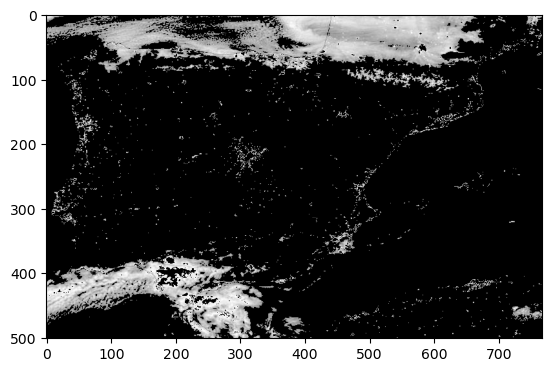

In [8]:
t1 = 100
t2 = 180

resultado_img, filtro_inicial = aplicamascara(img, t1, t2)

plt.imshow(resultado_img, cmap="gray")

In [46]:
#TAREA30

Text(0.5, 1.0, 'Resultado final filtrado')

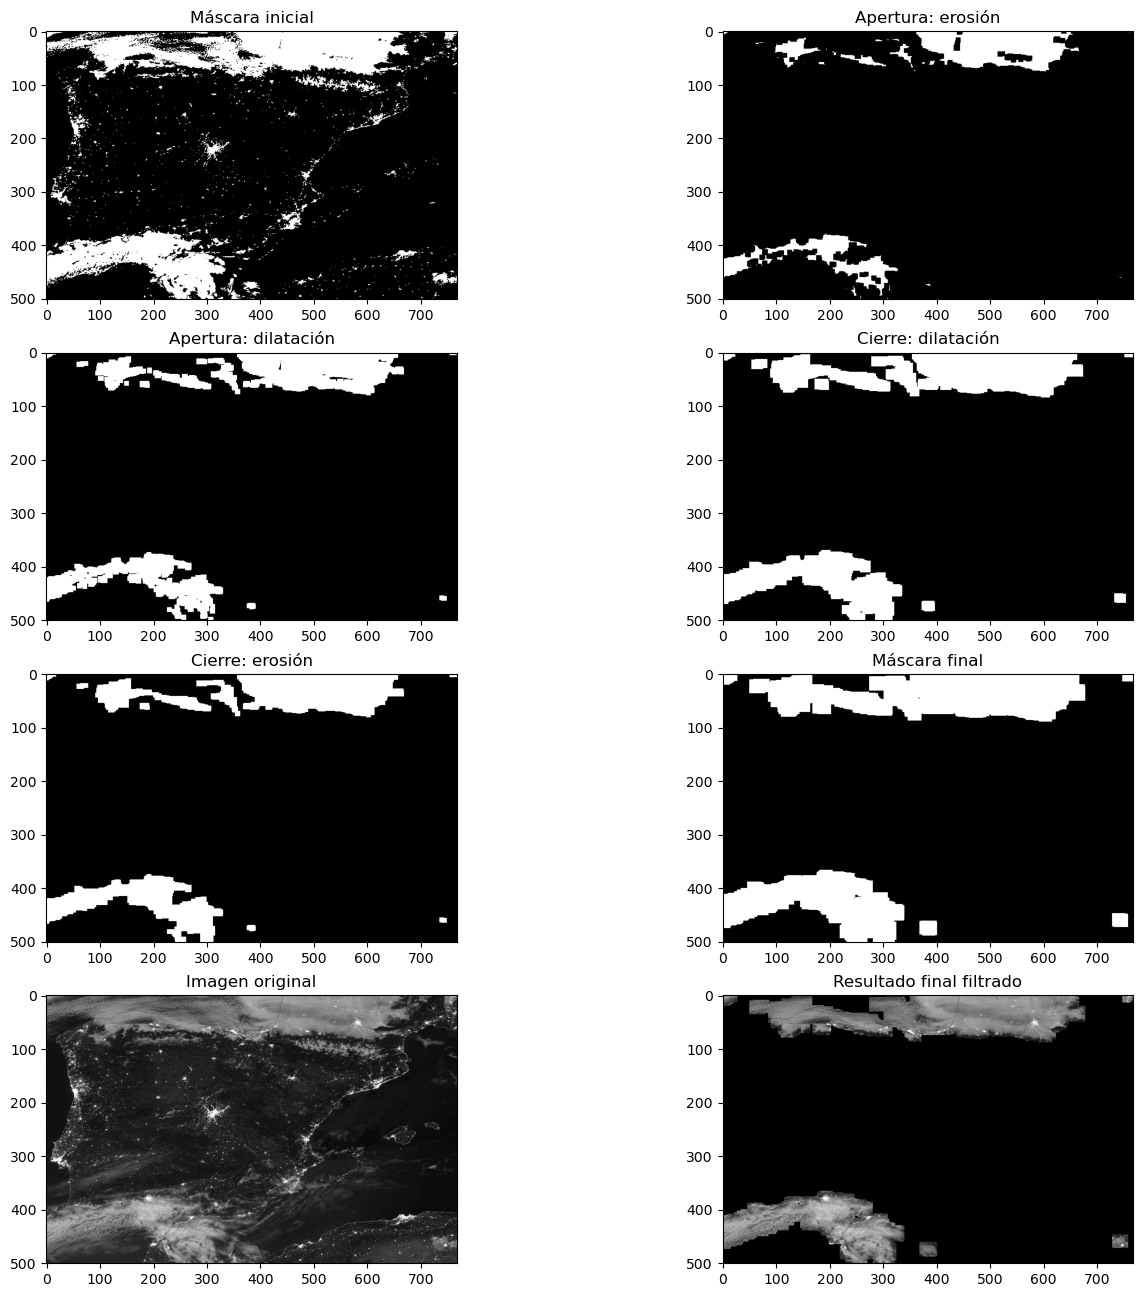

In [9]:
_, mask = cv.threshold(img, t1, t2, cv.THRESH_BINARY)
mask = mask / t2

fig, axs = plt.subplots(4, 2, figsize=(16, 16))

# Mostrar máscara base
axs[0,0].imshow(mask, cmap='gray')
axs[0,0].set_title("Máscara inicial")

# Kernel morfológico
kernel = np.ones((9, 9), np.uint8)

# --- Apertura manual ---
erosionada = cv.erode(mask, kernel)
abierta = cv.dilate(erosionada, kernel)

axs[0,1].imshow(erosionada, cmap="gray")
axs[0,1].set_title("Apertura: erosión")

axs[1,0].imshow(abierta, cmap="gray")
axs[1,0].set_title("Apertura: dilatación")

# --- Cierre manual ---
dilatada = cv.dilate(abierta, kernel)
cerrada = cv.erode(dilatada, kernel)

axs[1,1].imshow(dilatada, cmap="gray")
axs[1,1].set_title("Cierre: dilatación")

axs[2,0].imshow(cerrada, cmap="gray")
axs[2,0].set_title("Cierre: erosión")

# Expansión final
mascara_final = cv.dilate(cerrada, kernel, iterations=2)

axs[2,1].imshow(mascara_final, cmap="gray")
axs[2,1].set_title("Máscara final")

# Imagen filtrada final
img_filtrada_final = img * mascara_final

axs[3,0].imshow(img, cmap="gray")
axs[3,0].set_title("Imagen original")

axs[3,1].imshow(img_filtrada_final, cmap="gray")
axs[3,1].set_title("Resultado final filtrado")

In [25]:
#TAREA30
def operaciones_morf(alto_kernel=9, ancho_kernel=9):
    # Umbralización básica para obtener una máscara inicial
    _, mascara_ini = cv.threshold(img, 100, 180, cv.THRESH_BINARY)
    mascara_ini = mascara_ini / 180   # Normalización
    
    fig, ejes = plt.subplots(4, 2, figsize=(16, 16))

    # Mostrar la máscara original
    ejes[0,0].imshow(mascara_ini, cmap='gray')
    ejes[0,0].set_title("Máscara inicial")
    
    # Estructura morfológica
    estructura = np.ones((alto_kernel, ancho_kernel), np.uint8)
    
    # ---- APERTURA MANUAL: elimina ruido fino ----
    erosion_1 = cv.erode(mascara_ini, estructura)
    apertura = cv.dilate(erosion_1, estructura)

    ejes[0,1].imshow(erosion_1, cmap="gray")
    ejes[0,1].set_title("Apertura – fase 1 (erosión)")
    
    ejes[1,0].imshow(apertura, cmap="gray")
    ejes[1,0].set_title("Apertura – fase 2 (dilatación)")
    
    # ---- CIERRE MANUAL: refuerza regiones mayores ----
    dilat_1 = cv.dilate(apertura, estructura)
    cierre = cv.erode(dilat_1, estructura)

    ejes[1,1].imshow(dilat_1, cmap="gray")
    ejes[1,1].set_title("Cierre – fase 1 (dilatación)")

    ejes[2,0].imshow(cierre, cmap="gray")
    ejes[2,0].set_title("Cierre – fase 2 (erosión)")
    
    # Expansión final para consolidar contornos
    mascara_refinada = cv.dilate(cierre, estructura, iterations=2)

    ejes[2,1].imshow(mascara_refinada, cmap="gray")
    ejes[2,1].set_title("Máscara refinada final")
    
    # Comparación con imagen original
    ejes[3,0].imshow(img, cmap="gray")
    ejes[3,0].set_title("Imagen de entrada")
    
    resultado = img * mascara_refinada
    ejes[3,1].imshow(resultado, cmap="gray")
    ejes[3,1].set_title("Resultado tras aplicar máscara final")

    #A mayor tamaño de kernel, más fuerte es el efecto morfológico: se eliminan más detalles pequeños y las regiones se expanden o contraen más intensamente.


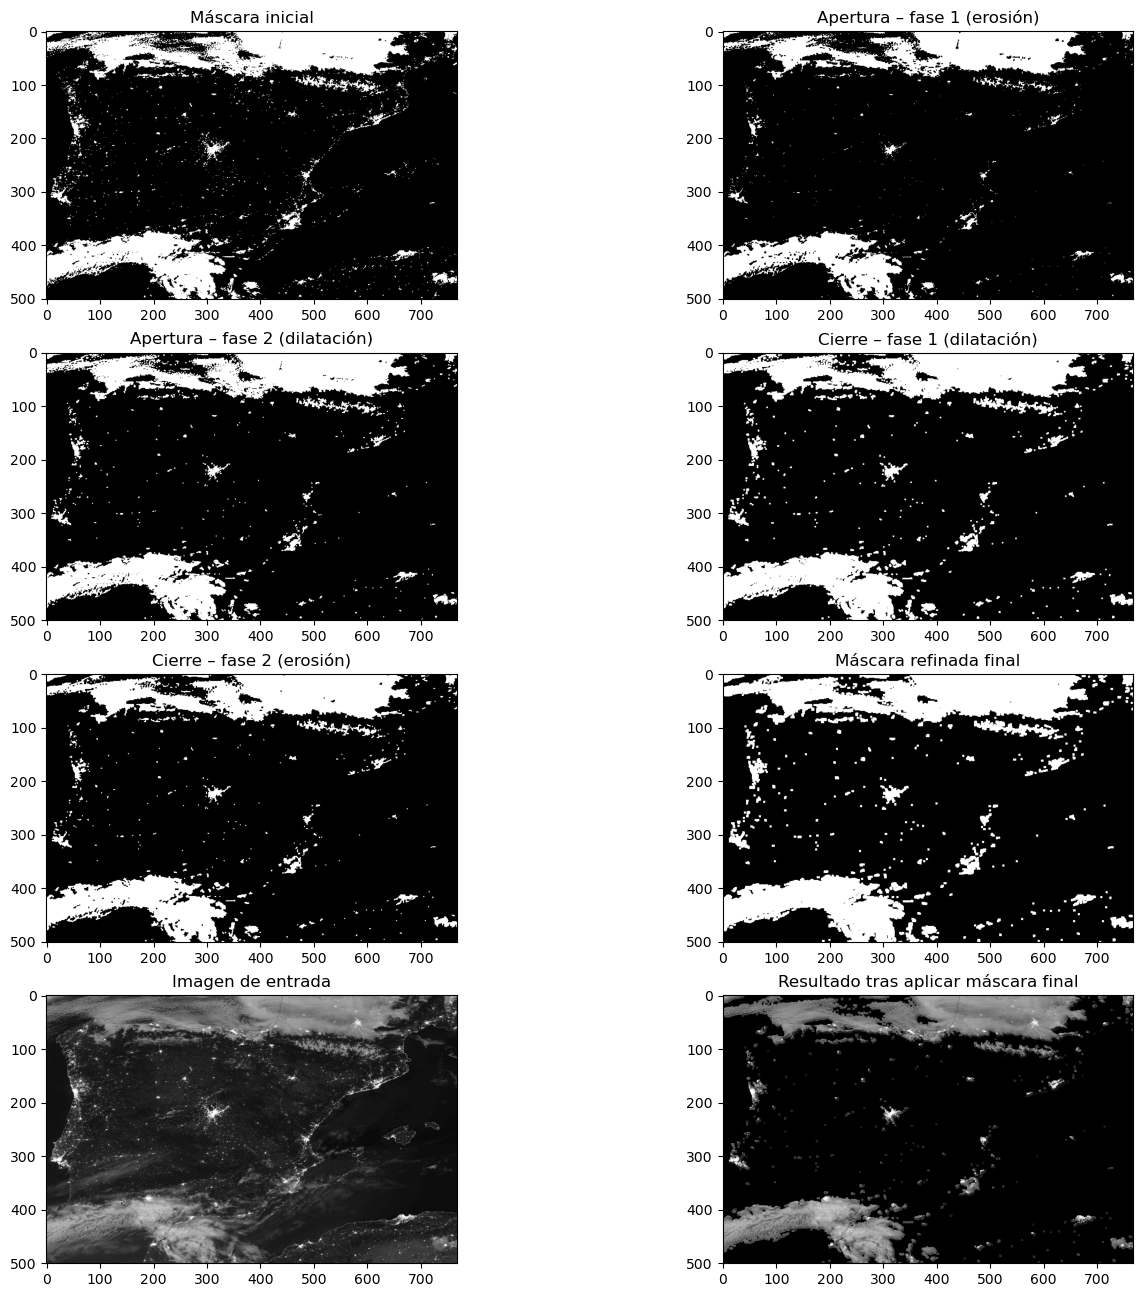

In [26]:
operaciones_morf(2,2)

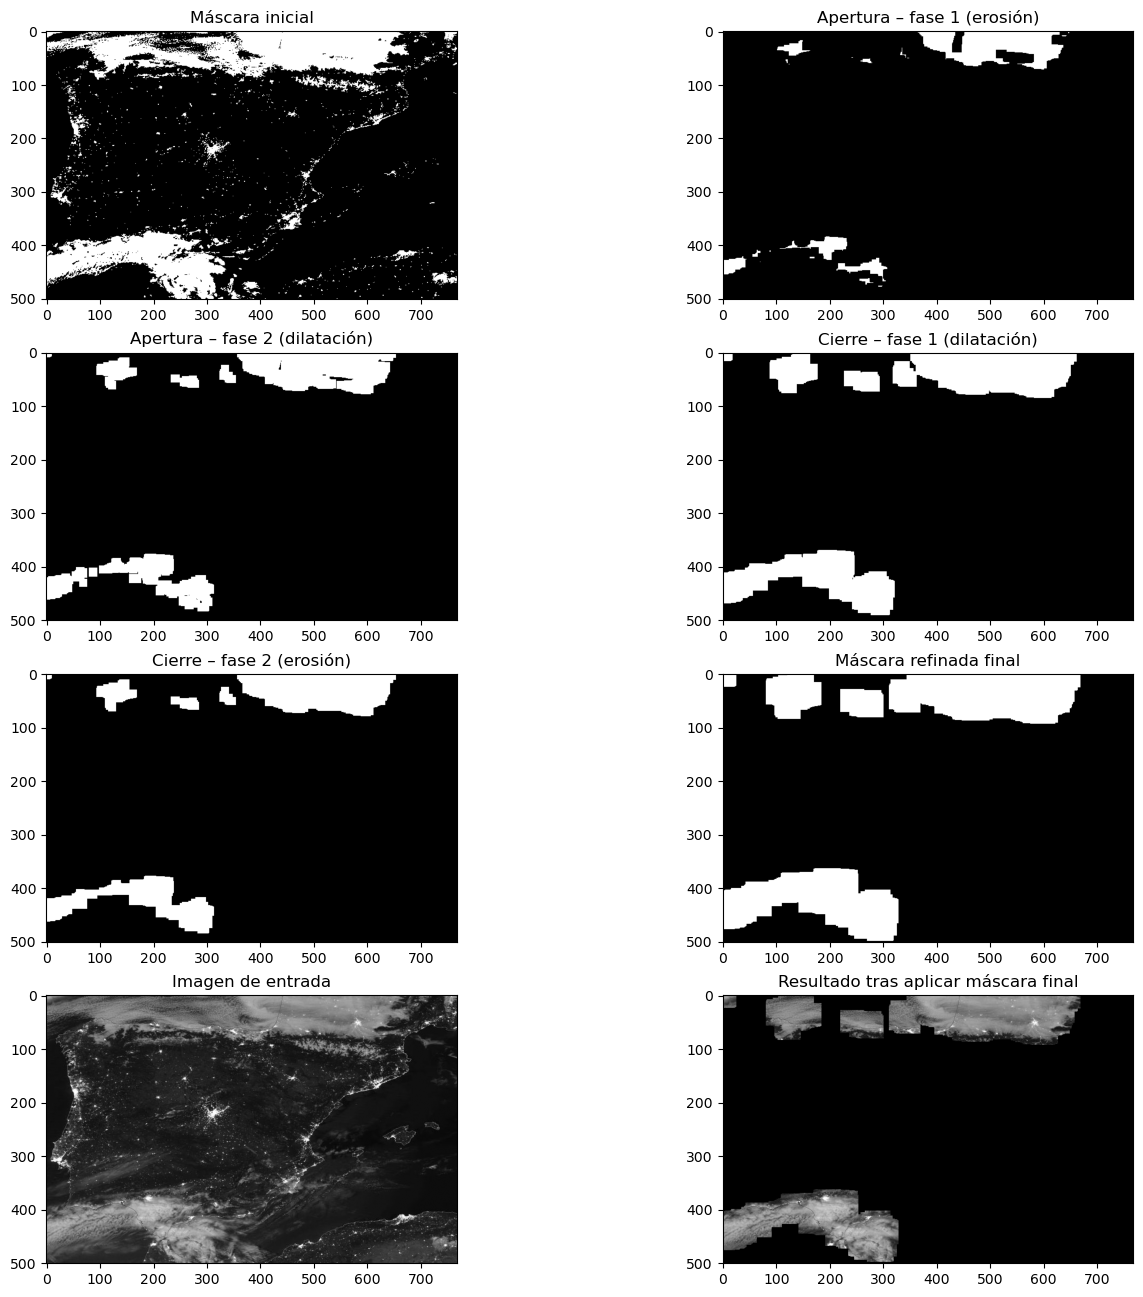

In [27]:
operaciones_morf(15,15)

Text(0.5, 1.0, 'Resultado tras enmascarar')

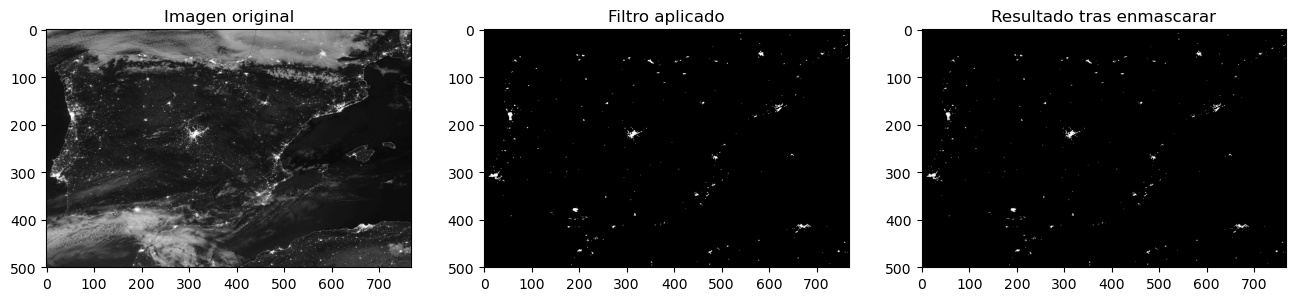

In [28]:
#TAREA31
filtro = mascara(img, 200, 255)
imagen_filtrada = img * filtro

figura, axes = plt.subplots(1, 3, figsize=(16, 16))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("Imagen original")

axes[1].imshow(filtro, cmap="gray")
axes[1].set_title("Filtro aplicado")

axes[2].imshow(imagen_filtrada, cmap="gray")
axes[2].set_title("Resultado tras enmascarar")

In [29]:
#TAREA32
def operaciones_mascara(mask, alto_kernel=3, ancho_kernel=3):
    # Preparación de la figura
    fig, panel = plt.subplots(4, 2, figsize=(16, 16))

    # Mostrar la máscara recibida
    panel[0,0].imshow(mask, cmap='gray')
    panel[0,0].set_title("Máscara de entrada")
    
    # Estructura morfológica
    elemento = np.ones((alto_kernel, ancho_kernel), np.uint8)
    
    # ---- APERTURA MANUAL (reduce ruido fino) ----
    erosion_step = cv.erode(mask, elemento)
    apertura_res = cv.dilate(erosion_step, elemento)

    panel[0,1].imshow(erosion_step, cmap="gray")
    panel[0,1].set_title("Apertura – etapa 1 (erosión)")
    
    panel[1,0].imshow(apertura_res, cmap="gray")
    panel[1,0].set_title("Apertura – etapa 2 (dilatación)")
    
    # ---- CIERRE MANUAL (refuerza áreas amplias) ----
    dilat_step = cv.dilate(apertura_res, elemento)
    cierre_res = cv.erode(dilat_step, elemento)

    panel[1,1].imshow(dilat_step, cmap="gray")
    panel[1,1].set_title("Cierre – etapa 1 (dilatación)")

    panel[2,0].imshow(cierre_res, cmap="gray")
    panel[2,0].set_title("Cierre – etapa 2 (erosión)")
    
    # ---- Ajuste final mediante dilataciones adicionales ----
    mascara_final = cv.dilate(cierre_res, elemento, iterations=2)

    panel[2,1].imshow(mascara_final, cmap="gray")
    panel[2,1].set_title("Máscara refinada final")
    
    # Imagen original y resultado
    panel[3,0].imshow(img, cmap="gray")
    panel[3,0].set_title("Imagen de referencia")
    
    resultado = img * mascara_final
    panel[3,1].imshow(resultado, cmap="gray")
    panel[3,1].set_title("Imagen filtrada con máscara final")


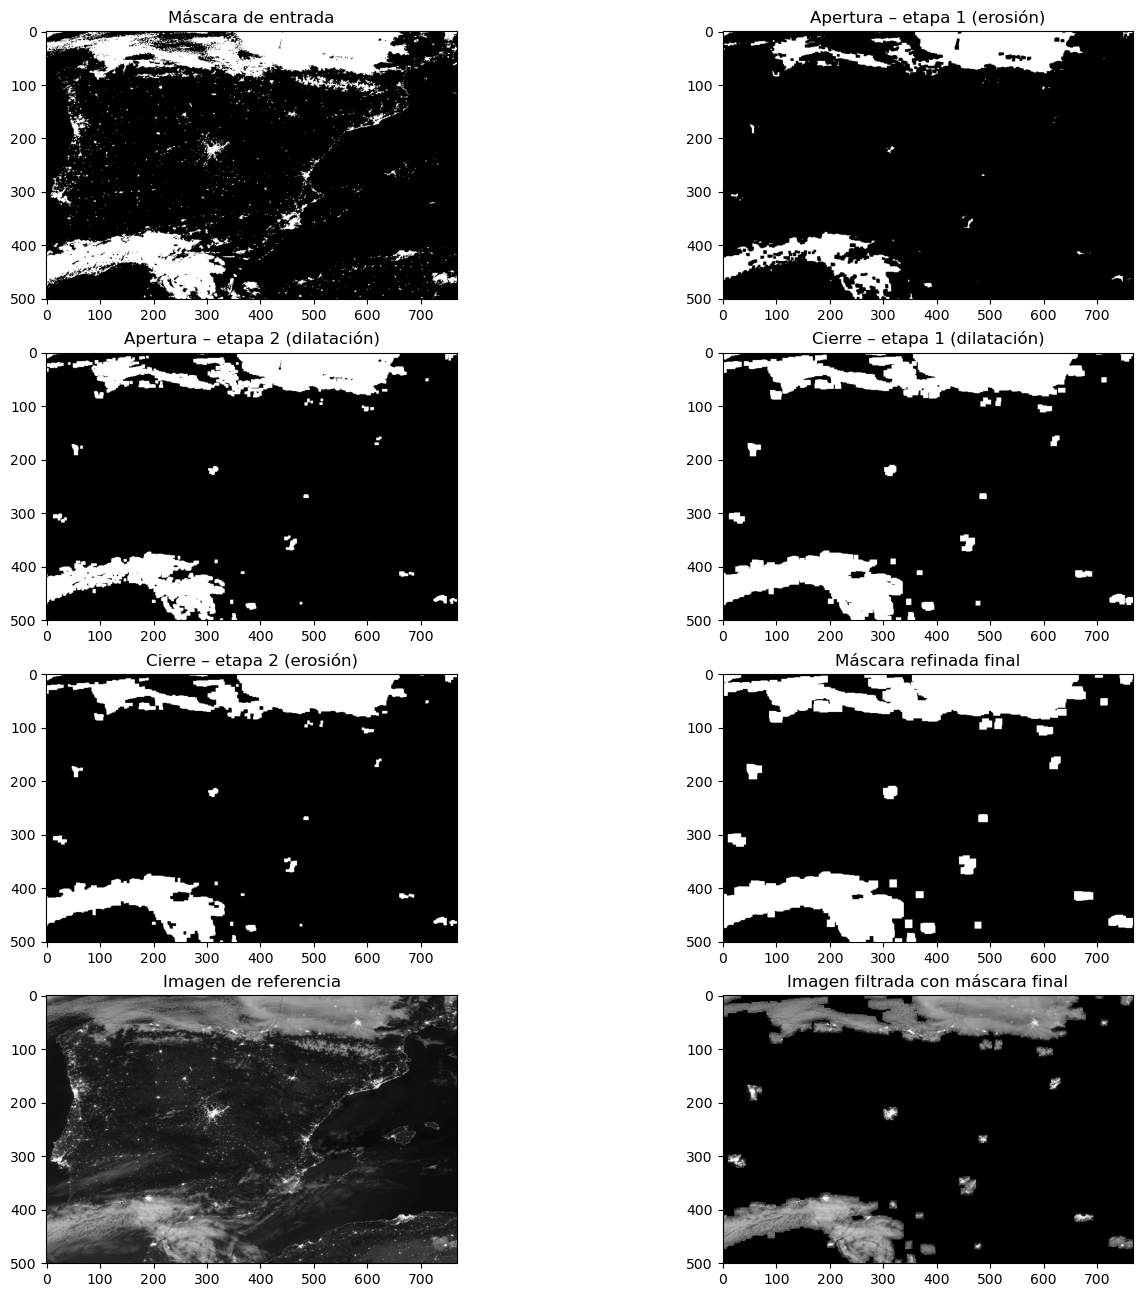

In [30]:
operaciones_mascara(mask, alto_kernel=5, ancho_kernel=5)